# Planta Física: Genetic algorithms

MA2015.202 · Team 08

- Aldo Tolentino Luna (A01668465)
- Emilio Estrada Pérez (A01770665)
- Juan Diego Rodríguez Espinoza (A01667431)

| Role | Member |
|:--|:--|
| Driver | Juan Diego |
| Reviewer | Emilio Estrada |
| Verifier | Aldo Tolentino |


Data: Recorded water demands during March 2025 

GitHub: https://github.com/Monknow/reto-planta-fisica

## 1. Problem Definition

The _Planta Física_ needs to allocate treated water to four buildings (Aulas I, Biblioteca, CEDETEC, Aulas II) to reduce the potable water consumed. If we don't provide enough treated water to meet each building's demands, then the remaining demand is fulfilled by potable water.

The total water demand of each building during March 2025 (monthly totals from the records) is:

- Aulas 1 = 847 m³
- Biblioteca = 462 m³
- Cedetec = 284.21 m³
- Aulas 2 = 683 m³

We suppose the maximum treated-water capacity for March 2025 is 1 410 m³ (a monthly total).

**Note:** The monthly capacity is a teaching assumption; it is not a partner-confirmed capacity.

All quantities in this notebook ($D_i$, $\sum_i D_i = 2276.21$ m³, $C$, $T$, $P$ and $E$) are monthly totals for March 2025, so the model applies only to this monthly exercise.

Each building has a reuse limit which represents the maximum percentage of the building's monthly demand that can be covered with treated water.

- Aulas 1 = 80%
- Biblioteca = 80%
- Cedetec = 60%
- Aulas 2 = 80%

**Note:** The reuse limits are teaching assumptions.

We can vary the reuse percentage within their limit. To describe each reuse percentage, we'll encode them together in a chromosome $k=(k_1,k_2,k_3,k_4)$ Using integers: 

- $k_1,k_2,k_4\in\{0,\ldots,8\}$ 
- $k_3\in\{0,\ldots,6\}$. 

Where $x_i=k_i/10$. For example, gene 6 represents 60% reuse. This means we have $9\times9\times7\times9=5103$ combinations which we'll navigate using the genetic algorithm to find the best combination.

The next table summarizes each building's details:


| Building   | Demand $D_i$ ($m^3$) | Domain of $k_i$    | Maximum reuse |
|:-----------|---------------------:|:------------------:|--------------:|
| Aulas 1    | 847.00               | $\{0,\ldots,8\}$   | 80%           |
| Biblioteca | 462.00               | $\{0,\ldots,8\}$   | 80%           |
| Cedetec    | 284.21               | $\{0,\ldots,6\}$   | 60%           |
| Aulas 2    | 683.00               | $\{0,\ldots,8\}$   | 80%           |

In [1]:
import numpy as np

BUILDINGS = ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
DEMAND = np.array([847.0, 462.0, 284.21, 683.0])  # m3, monthly totals, March 2025
LIMITS = np.array([8, 8, 6, 8])  # integer levels; fractions = levels / 10
CAPACITY = 1410.0  # m3 per month (March 2025); teaching assumption, not confirmed plant capacity

## 2. The Fitness Function

Our decision variable is the reuse percentage on each building. To evaluate each combination, we'll need to define a fitness function that determines the efficiency of each chromosome. To do so, we'll define the following values:

**Treated Water:** The amount of treated water the system used, which is just the sum of the treated water for each building.

$$\text{Treated water: } T_i = D_i\frac{k_i}{10}, \qquad T= \sum_i T_i = \frac{1}{10} \sum_i D_i k_i$$

**Potable Water:** The amount of potable water we had to inject in the system to satisfy demand. It follows is the total demand minus the treated water the system was able to use.

$$\text{Potable water: } P_i = D_i - T_i, \qquad P=\sum_i P_i = \sum_iD_i-T$$

**Excess capacity:** The system cannot provide treated water ($T$) beyond its established capacity ($C$). Once $T$ is greater than $C$, the system becomes unfeasiable since we are using treated water we don't even have. The excess capacity represents the amount of *unavailable* treated water the system is trying to use. 

$$\text{Excess capacity: } E=\max(0,T-C)$$

In other words, once the Excess capacity is greater than zero, the system is unfesiable.

With that said, our goal is to minimize $P$ (the amount of potable water the system requires), subject to the gene domains and $T\le C$ (using the available treated water). 

To get a better sense of the efficiency of the system, instead of directly minimizing $P$, we'll minimize $F= \frac{P}{\sum D_i}$, which represents the ratio of the demand that's satisified by potable water. Our fitness function then is then F.  

**Lower fitness is better.**

Note that, if we use the current $F$ as the fitness function, we could cheat the system by ignoring the system's capacity, setting $P$ to zero and $T$ to the maximum, resulting in a perfect $F = 0$. To avoid this, whenever the system is unfeasible we set  $F=1+\frac{E}{C}$. This way, a feasible candidate has $F\le1$; an unfeasible candidate has $F>1$

We use a numerical tolerance of $10^{-8}$ m³.

### Calculations by Hand

Before running the code, let's calculate by hand three candidates. For each one we first compute the treated and potable water building by building, $T_i = D_i\frac{k_i}{10}$ and $P_i = D_i - T_i$, check that $T_i + P_i = D_i$, and then add the rows to get $T$ and $P$. All volumes are monthly totals for March 2025, in m³.

$$\sum_i D_i = D_1+D_2+D_3+D_4 = 847.00+462.00+284.21+683.00 = 2276.21\ \text{m}^3$$

1. Constant reuse: $k=(6,6,6,6)$

Every $k_i=6$, therefore $x_i = \frac{6}{10} = 0.6$. The four products are:

- $T_1 = 847 \times 0.6 = 508.200$ m³
- $T_2 = 462 \times 0.6 = 277.200$ m³
- $T_3 = 284.21 \times 0.6 = 170.526$ m³
- $T_4 = 683 \times 0.6 = 409.800$ m³

| Building | $D_i$ (m³) | $k_i$ | $x_i=k_i/10$ | $T_i=D_i x_i$ (m³) | $P_i=D_i-T_i$ (m³) | Check $T_i+P_i=D_i$ |
|:--|--:|--:|--:|--:|--:|:-:|
| Aulas 1 | 847.00 | 6 | 0.6 | 847 × 0.6 = 508.200 | 847.00 − 508.200 = 338.800 | 508.200 + 338.800 = 847.00 ✓ |
| Biblioteca | 462.00 | 6 | 0.6 | 462 × 0.6 = 277.200 | 462.00 − 277.200 = 184.800 | 277.200 + 184.800 = 462.00 ✓ |
| Cedetec | 284.21 | 6 | 0.6 | 284.21 × 0.6 = 170.526 | 284.21 − 170.526 = 113.684 | 170.526 + 113.684 = 284.21 ✓ |
| Aulas 2 | 683.00 | 6 | 0.6 | 683 × 0.6 = 409.800 | 683.00 − 409.800 = 273.200 | 409.800 + 273.200 = 683.00 ✓ |
| **Total** | **2276.21** | | | **1365.726** | **910.484** | 1365.726 + 910.484 = 2276.21 ✓ |

$$
\begin{aligned}
& T = \sum_i T_i = 508.200+277.200+170.526+409.800 = 1365.726\ \text{m}^3 \\
& P = \sum_i P_i = 338.800+184.800+113.684+273.200 = 910.484\ \text{m}^3 \quad (= 2276.21-1365.726) \\ \\

& \text{Now, is this combination feasible?} \\ \\

& E = \max(0,\,T-C) \\
& T-C = 1365.726-1410 = -44.274 \le 0 \\
& \text{Then } E = \max(0,\ -44.274) = 0\ \text{m}^3 \\ \\

& \text{Since it is feasible } (T\le C), \text{ let's calculate the fitness function as:} \\ \\

& F = \frac{P}{\sum_i D_i} = \frac{910.484}{2276.21} = 0.4
\end{aligned}
$$

2. Zero reuse: $k = (0, 0, 0, 0)$

Every $k_i=0$, therefore $x_i = \frac{0}{10} = 0$, so every product is zero ($847 \times 0 = 462 \times 0 = 284.21 \times 0 = 683 \times 0 = 0$ m³) and each building is supplied only with potable water.

| Building | $D_i$ (m³) | $k_i$ | $x_i=k_i/10$ | $T_i=D_i x_i$ (m³) | $P_i=D_i-T_i$ (m³) | Check $T_i+P_i=D_i$ |
|:--|--:|--:|--:|--:|--:|:-:|
| Aulas 1 | 847.00 | 0 | 0.0 | 847 × 0.0 = 0.000 | 847.00 − 0.000 = 847.000 | 0.000 + 847.000 = 847.00 ✓ |
| Biblioteca | 462.00 | 0 | 0.0 | 462 × 0.0 = 0.000 | 462.00 − 0.000 = 462.000 | 0.000 + 462.000 = 462.00 ✓ |
| Cedetec | 284.21 | 0 | 0.0 | 284.21 × 0.0 = 0.000 | 284.21 − 0.000 = 284.210 | 0.000 + 284.210 = 284.21 ✓ |
| Aulas 2 | 683.00 | 0 | 0.0 | 683 × 0.0 = 0.000 | 683.00 − 0.000 = 683.000 | 0.000 + 683.000 = 683.00 ✓ |
| **Total** | **2276.21** | | | **0.000** | **2276.210** | 0.000 + 2276.210 = 2276.21 ✓ |

$$
\begin{aligned}
& T = \sum_i T_i = 0\ \text{m}^3 \\
& P = \sum_i P_i = 2276.21-0 = 2276.21\ \text{m}^3 \\ \\

& \text{Now, is this combination feasible?} \\ \\

& E = \max(0,\,T-C) \\
& T-C = 0-1410 = -1410 \le 0 \\
& \text{Then } E = \max(0,\ -1410) = 0\ \text{m}^3 \\ \\

& \text{Since it is feasible } (T\le C), \text{ let's calculate the fitness function as:} \\ \\

& F = \frac{P}{\sum_i D_i} = \frac{2276.21}{2276.21} = 1.0
\end{aligned}
$$

3. Maximum levels in each domain: $k = (8, 8, 6, 8)$

Here $k_i=8$ for $i\in\{1,2,4\}$ and $k_3=6$, therefore $x_1=x_2=x_4=0.8$ and $x_3=0.6$. The four products are:

- $T_1 = 847 \times 0.8 = 677.600$ m³
- $T_2 = 462 \times 0.8 = 369.600$ m³
- $T_3 = 284.21 \times 0.6 = 170.526$ m³
- $T_4 = 683 \times 0.8 = 546.400$ m³

| Building | $D_i$ (m³) | $k_i$ | $x_i=k_i/10$ | $T_i=D_i x_i$ (m³) | $P_i=D_i-T_i$ (m³) | Check $T_i+P_i=D_i$ |
|:--|--:|--:|--:|--:|--:|:-:|
| Aulas 1 | 847.00 | 8 | 0.8 | 847 × 0.8 = 677.600 | 847.00 − 677.600 = 169.400 | 677.600 + 169.400 = 847.00 ✓ |
| Biblioteca | 462.00 | 8 | 0.8 | 462 × 0.8 = 369.600 | 462.00 − 369.600 = 92.400 | 369.600 + 92.400 = 462.00 ✓ |
| Cedetec | 284.21 | 6 | 0.6 | 284.21 × 0.6 = 170.526 | 284.21 − 170.526 = 113.684 | 170.526 + 113.684 = 284.21 ✓ |
| Aulas 2 | 683.00 | 8 | 0.8 | 683 × 0.8 = 546.400 | 683.00 − 546.400 = 136.600 | 546.400 + 136.600 = 683.00 ✓ |
| **Total** | **2276.21** | | | **1764.126** | **512.084** | 1764.126 + 512.084 = 2276.21 ✓ |

$$
\begin{aligned}
& T = \sum_i T_i = 677.600+369.600+170.526+546.400 = 1764.126\ \text{m}^3 \\
& P = \sum_i P_i = 169.400+92.400+113.684+136.600 = 512.084\ \text{m}^3 \quad (= 2276.21-1764.126) \\ \\

& \text{Now, is this combination feasible?} \\ \\

& E = \max(0,\,T-C) \\
& T-C = 1764.126-1410 = 354.126 > 0 \\
& \text{Then } E = \max(0,\ 354.126) = 354.126\ \text{m}^3 \\ \\

& \text{Since it is not feasible } (T>C), \text{ let's calculate the fitness function as:} \\ \\

& F = 1+\frac{E}{C} = 1+\frac{354.126}{1410} = 1.25115319
\end{aligned}
$$

In [2]:
def evaluate(genes: np.ndarray) -> dict:
    """Return physical totals and fitness (lower is better) for four integer genes."""
    genes = np.asarray(genes)

    if genes.shape != (4,) or not np.issubdtype(genes.dtype, np.integer):
        raise ValueError("Expected four integer genes in building order.")
    if np.any(genes < 0) or np.any(genes > LIMITS):
        raise ValueError("Genes outside the allowed building domains.")

    treated = float(np.sum(DEMAND * genes / 10))
    potable = float(np.sum(DEMAND) - treated)
    excess = max(0.0, treated - CAPACITY)
    feasible = excess <= 1e-8  # numerical tolerance in m^3

    fitness = potable / float(np.sum(DEMAND)) if feasible else 1 + excess / CAPACITY

    return {
        "treated": treated,
        "potable": potable,
        "excess": excess,
        "feasible": feasible,
        "fitness": fitness,
    }

In [3]:
cases = [np.zeros(4, dtype=int), np.array([6, 6, 6, 6]), LIMITS.copy()]

for genes in cases:
    print(genes, evaluate(genes))

assert np.isclose(evaluate(cases[1])["potable"], 910.484)
assert evaluate(cases[1])["feasible"]
assert not evaluate(cases[2])["feasible"]

[0 0 0 0] {'treated': 0.0, 'potable': 2276.21, 'excess': 0.0, 'feasible': True, 'fitness': 1.0}
[6 6 6 6] {'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}
[8 8 6 8] {'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}


We compare our manual values from the previous section with the output of `evaluate`. Volumes are rounded to 3 decimals (m³) and $F$ to 8 decimals. The difference column is $|\text{manual} - \text{evaluator}|$ computed with the unrounded evaluator output.

| Case $k$ | Metric | Manual value | Evaluator value | Difference |
|:--|:--|--:|--:|--:|
| $(6,6,6,6)$ | `treated` $T$ (m³) | 1365.726 | 1365.726 | $2.3\times10^{-13}$ |
| | `potable` $P$ (m³) | 910.484 | 910.484 | $1.1\times10^{-13}$ |
| | `excess` $E$ (m³) | 0.000 | 0.000 | 0 |
| | `feasible` | True | True | — (equal) |
| | `fitness` $F$ | 0.40000000 | 0.40000000 | $5.6\times10^{-17}$ |
| $(0,0,0,0)$ | `treated` $T$ (m³) | 0.000 | 0.000 | 0 |
| | `potable` $P$ (m³) | 2276.210 | 2276.210 | 0 |
| | `excess` $E$ (m³) | 0.000 | 0.000 | 0 |
| | `feasible` | True | True | — (equal) |
| | `fitness` $F$ | 1.00000000 | 1.00000000 | 0 |
| $(8,8,6,8)$ | `treated` $T$ (m³) | 1764.126 | 1764.126 | $2.3\times10^{-13}$ |
| | `potable` $P$ (m³) | 512.084 | 512.084 | $1.1\times10^{-13}$ |
| | `excess` $E$ (m³) | 354.126 | 354.126 | $2.3\times10^{-13}$ |
| | `feasible` | False | False | — (equal) |
| | `fitness` $F$ | 1.25115319 | 1.25115319 | $1.5\times10^{-9}$ |

All five keys agree for the three cases. The nonzero differences of order $10^{-13}$ come from floating-point representation in the code, and the $1.5\times10^{-9}$ in $F$ for $(8,8,6,8)$ comes from rounding our manual value to 8 decimals (the evaluator gives $1.2511531914\ldots$). None of them come from the model.

We also see that it isn't feasible to set the reuse percentage to the maximum, so we'll have to make sacrifices about which genes to use. From our manual tests, the $[6, 6, 6, 6]$ chromosome had the best fitness.

## 3. We generate a population

We define the population a the list of candidates. We sample each gene within its domain, including both endpoints. Note that sampling does not guarantee a feasible solution. However, we hope the fitness punishment for unfeasible solutions will rule out those chromosomes.

In [4]:
def random_individual(rng: np.random.Generator) -> np.ndarray:
    """Sample one valid discrete chromosome; capacity is checked by evaluate."""
    return rng.integers(0, LIMITS + 1)


rng_demo = np.random.default_rng(42)
population_demo = [random_individual(rng_demo) for _ in range(4)]
for genes in population_demo:
    print(genes, evaluate(genes)["fitness"])

[0 6 4 3] 0.7382561362967388
[3 7 0 6] 0.5662526744017468
[1 0 3 8] 0.6852825530157587
[6 6 5 7] 0.38248008751389373


## 4. We select parents through tournaments

We sample two distinct candidates and choose the one with lower $F$. We repeat the process to select another parent. Note that the same individual can win several tournaments. Selection favors lower fitness without always sorting the entire population. 

See that we return a copy to protect the original.

In [5]:
def tournament(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the better of two sampled individuals."""
    indices = rng.choice(len(population), size=2, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()


parent_a = tournament(population_demo, rng_demo)
parent_b = tournament(population_demo, rng_demo)
print(parent_a, parent_b)

[3 7 0 6] [3 7 0 6]


## 5. We combine information through one-point crossover

We choose a cut between gene positions and join the beginning of one parent with the end of the other. Note that each gene keeps its position, so the first gene always describes Aulas 1, the second Biblioteca, and so on. For parents $(6,6,6,6)$ and $(8,2,4,3)$ with cut 2, we obtain $(6,6,4,3)$.

Since every gene comes from a parent, the child always stays inside the gene domains. However, nothing guarantees it respects the capacity, so a child can be unfeasible and we let $F$ punish it. Also note that if both tournaments return the same individual, the child is just a copy of that parent.

In [6]:
def crossover(
    parent_a: np.ndarray, parent_b: np.ndarray, rng: np.random.Generator
) -> np.ndarray:
    """Create one child using a cut between genes and preserving their positions."""
    cut = int(rng.integers(1, len(LIMITS)))
    return np.concatenate((parent_a[:cut], parent_b[cut:]))


child_demo = crossover(parent_a, parent_b, rng_demo)
print(child_demo, evaluate(child_demo))

[3 7 0 6] {'treated': 987.3, 'potable': 1288.91, 'excess': 0.0, 'feasible': True, 'fitness': 0.5662526744017468}


## 6. We introduce variation through mutation

Crossover only recombines genes that already exist in the population, so we need mutation to try new values. We apply the probability to **each gene** instead of the whole chromosome, and a selected gene moves one valid level up or down. At zero it can only go up, and at its maximum it can only go down.

With $p=0.25$ and four genes, we expect one mutated gene per child on average, but not exactly one: some children won't mutate at all and others will mutate two or more. Note that mutation can improve or worsen $F$, and it can even turn a feasible child into an unfeasible one.

In [7]:
def mutate(
    child: np.ndarray, probability: float, rng: np.random.Generator
) -> np.ndarray:
    """Independently move each selected gene one valid discrete step."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            result[i] = rng.choice(neighbors)
    return result


mutated_demo = mutate(child_demo, 0.25, rng_demo)
print(child_demo, mutated_demo, evaluate(mutated_demo))

[3 7 0 6] [3 7 0 7] {'treated': 1055.6, 'potable': 1220.6100000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.5362466556249205}


## 7. We replace the population and preserve one elite

We copy the best individual without changing it and fill the remaining positions with children, so the population size stays constant. This is called elitism: the best fitness can never get worse from one generation to the next. Note that this doesn't mean we found the optimum, only that we don't lose the best candidate we've seen.

See that we copy the elite and only mutate the children, so mutating a child never changes its parent or the elite. If no child beats the elite, the best fitness stays the same, which is what we see in the demo below.

In [8]:
def next_generation(
    population: list, probability: float, rng: np.random.Generator
) -> list:
    """Preserve one independent elite and replace all other individuals."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover(parent_a, parent_b, rng)
        replacement.append(mutate(child, probability, rng))
    return replacement


replacement_demo = next_generation(population_demo, 0.25, rng_demo)
print(min(evaluate(x)["fitness"] for x in population_demo))
print(min(evaluate(x)["fitness"] for x in replacement_demo))

0.38248008751389373
0.38248008751389373


## 8. We complete the cycle

We initialize the population and then repeat selection, crossover, mutation and replacement for a fixed number of generations. We record the best $F$ at initialization and after each generation, so 20 generations give us 21 values. Don't expect an improvement at every step: because of elitism the curve never goes up, but it can stay flat for many generations.

In [9]:
def run_ga(
    population_size: int = 20,
    generations: int = 20,
    mutation_probability: float = 0.25,
    seed: int = 42,
) -> dict:
    """Run a small canonical GA and retain the best fitness at each generation."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation(population, mutation_probability, rng)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

## 9. We run the baseline and a mutation variation

We use 20 individuals, 20 generations and seed 42. In the variation, we change only the per-gene mutation probability from 0.25 to 0.50, and keep the data, gene domains, capacity and all other parameters fixed. Note that this compares two executions; it doesn't establish that one configuration is better than the other in general.

This is the same-code comparison we need for the Final. For the Development, we would keep the baseline separately, make a substantive change to one operator, and compare both versions with $p_m=0.25$ in each run.

In [10]:
CONFIG = {"population_size": 20, "generations": 20, "mutation_probability": 0.25, "seed": 42}

baseline = run_ga(**CONFIG)
variant_config = {**CONFIG, "mutation_probability": 0.50}
variant = run_ga(**variant_config)

for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    print(label, "genes =", result["genes"], "fractions =", result["genes"] / 10)
    print(result["metrics"])

p=0.25 genes = [7 4 3 8] fractions = [0.7 0.4 0.3 0.8]
{'treated': 1409.363, 'potable': 866.847, 'excess': 0.0, 'feasible': True, 'fitness': 0.38082909749100474}
p=0.50 genes = [5 7 4 8] fractions = [0.5 0.7 0.4 0.8]
{'treated': 1406.984, 'potable': 869.2260000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.3818742558902738}


## 10. We visualize and interpret

In the plot, the horizontal axis is the generation and the vertical axis is the best fitness. A decrease means improvement, and a flat segment means no child beat the best value we were already keeping. Note that a descending curve alone doesn't tell us the solution is valid, so we always connect it back to feasibility and water volumes.

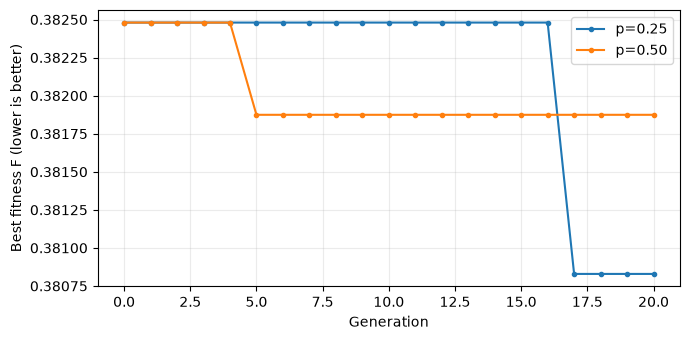

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    ax.plot(range(len(result["history"])), result["history"], marker=".", label=label)
ax.set(xlabel="Generation", ylabel="Best fitness F (lower is better)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

The only parameter we changed is the mutation probability, from $p=0.25$ to $p=0.50$. The next table compares the best chromosome of each run:

| | $p=0.25$ | $p=0.50$ |
|:--|--:|--:|
| Best chromosome $k$ | $(7,4,3,8)$ | $(5,7,4,8)$ |
| Reuse per building | 70%, 40%, 30%, 80% | 50%, 70%, 40%, 80% |
| Treated water $T$ ($m^3$) | 1409.363 | 1406.984 |
| Potable water $P$ ($m^3$) | 866.847 | 869.226 |
| Excess capacity $E$ ($m^3$) | 0 | 0 |
| Best fitness $F$ | 0.38083 | 0.38187 |
| Feasible | Yes | Yes |

Both runs end with a feasible solution, and both use almost all of the treated water available: they stay less than 3 $m^3$ below the capacity of 1 410 $m^3$. Compared to our best hand calculation, $(6,6,6,6)$ with $F=0.4$, both improve the fitness, since they take better advantage of the capacity.

Both runs start from the same best individual, with $F\approx0.38248$. With $p=0.25$ the curve stays flat until generation 17, when a child finally beats the elite. With $p=0.50$ the improvement appears earlier, at generation 5, and then the curve stays flat. In both cases, a plateau means that no child was better than the elite, and not that the search is finished.

Note that, for a feasible candidate, $F=\frac{P}{\sum_i D_i}=1-\frac{T}{\sum_i D_i}$. In other words, the algorithm is really looking for the combination whose $T$ gets as close as possible to $C$ without going over it. Many different chromosomes can do that, which is why the two runs end with different genes and almost the same $F$.

The difference between runs is $\approx0.001$ in $F$, which is about 2.4 $m^3$ of potable water over March 2025. With a single seed per configuration, we can't say that $p=0.50$ is worse than $p=0.25$. We only know that, with seed 42, the baseline ended slightly better, and that the variant found its improvement sooner. We would need several seeds to say anything more general. We also don't claim either result is the global optimum, because the GA doesn't guarantee it.

## 11. We check reproduction

We repeat the baseline with the same seed and check that the genes and the history match. We also restart the kernel and run the notebook from top to bottom, to make sure the results don't depend on cells we executed earlier. Note that this is a technical check, not a third experimental configuration. The last assertion checks elitism: the best fitness never goes up from one generation to the next.

In [12]:
repeated = run_ga(**CONFIG)
np.testing.assert_array_equal(baseline["genes"], repeated["genes"])
np.testing.assert_array_equal(baseline["history"], repeated["history"])
assert np.all(np.diff(baseline["history"]) <= 1e-12)
print("Reproduction and elitism checked.")

Reproduction and elitism checked.


## 12. Keep evidence in the same notebook

- **Research (15%)**: A1 formulation and assumptions (60/100); A2 hand calculation and comparison with the evaluator (40/100).
- **Development (15%)**: B1 functional cycle and justified substantive modification of one operator (70/100); B2 reproducibility and controlled baseline/variant comparison (30/100). Use $p_m=0.25$ for both versions.
- **Final (30%)**: C1 explanation of one generation (40/100); C2 same-code comparison of mutation probabilities 0.25/0.50 and its plot (35/100); C3 physical interpretation and model limitations (25/100).

For Final, retain earlier sections and add your team's explanation. Identify the supplied baseline and any team changes. If you still have only the baseline, identify it as unmodified and complete the Final analysis; the Development penalty will not be applied again. Keep the supplied environment files beside the notebook. The written team code examination will contribute 10% and the individual article examination will contribute 30%. Consult the [guide](challenge_guide_planta_fisica.pdf) and the detailed instructions in Canvas for performance levels and dates.

## Provenance and environment

We use the four March 2025 records from the supplied water-consumption data and the instructor-calibrated teaching limits. Notebook metadata retains the records and source hashes. The monthly case and code are self-contained.

With Python 3.12-3.14 and the supplied environment files, prepare the environment with `uv sync --locked` and open Jupyter with `uv run jupyter lab`. NumPy performs the calculations and Matplotlib draws the plot. Results describe this teaching model; they do not establish a validated hydraulic or sanitary recommendation.